In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
pip install keras

In [3]:
pip install tensorflow

RESNET 50

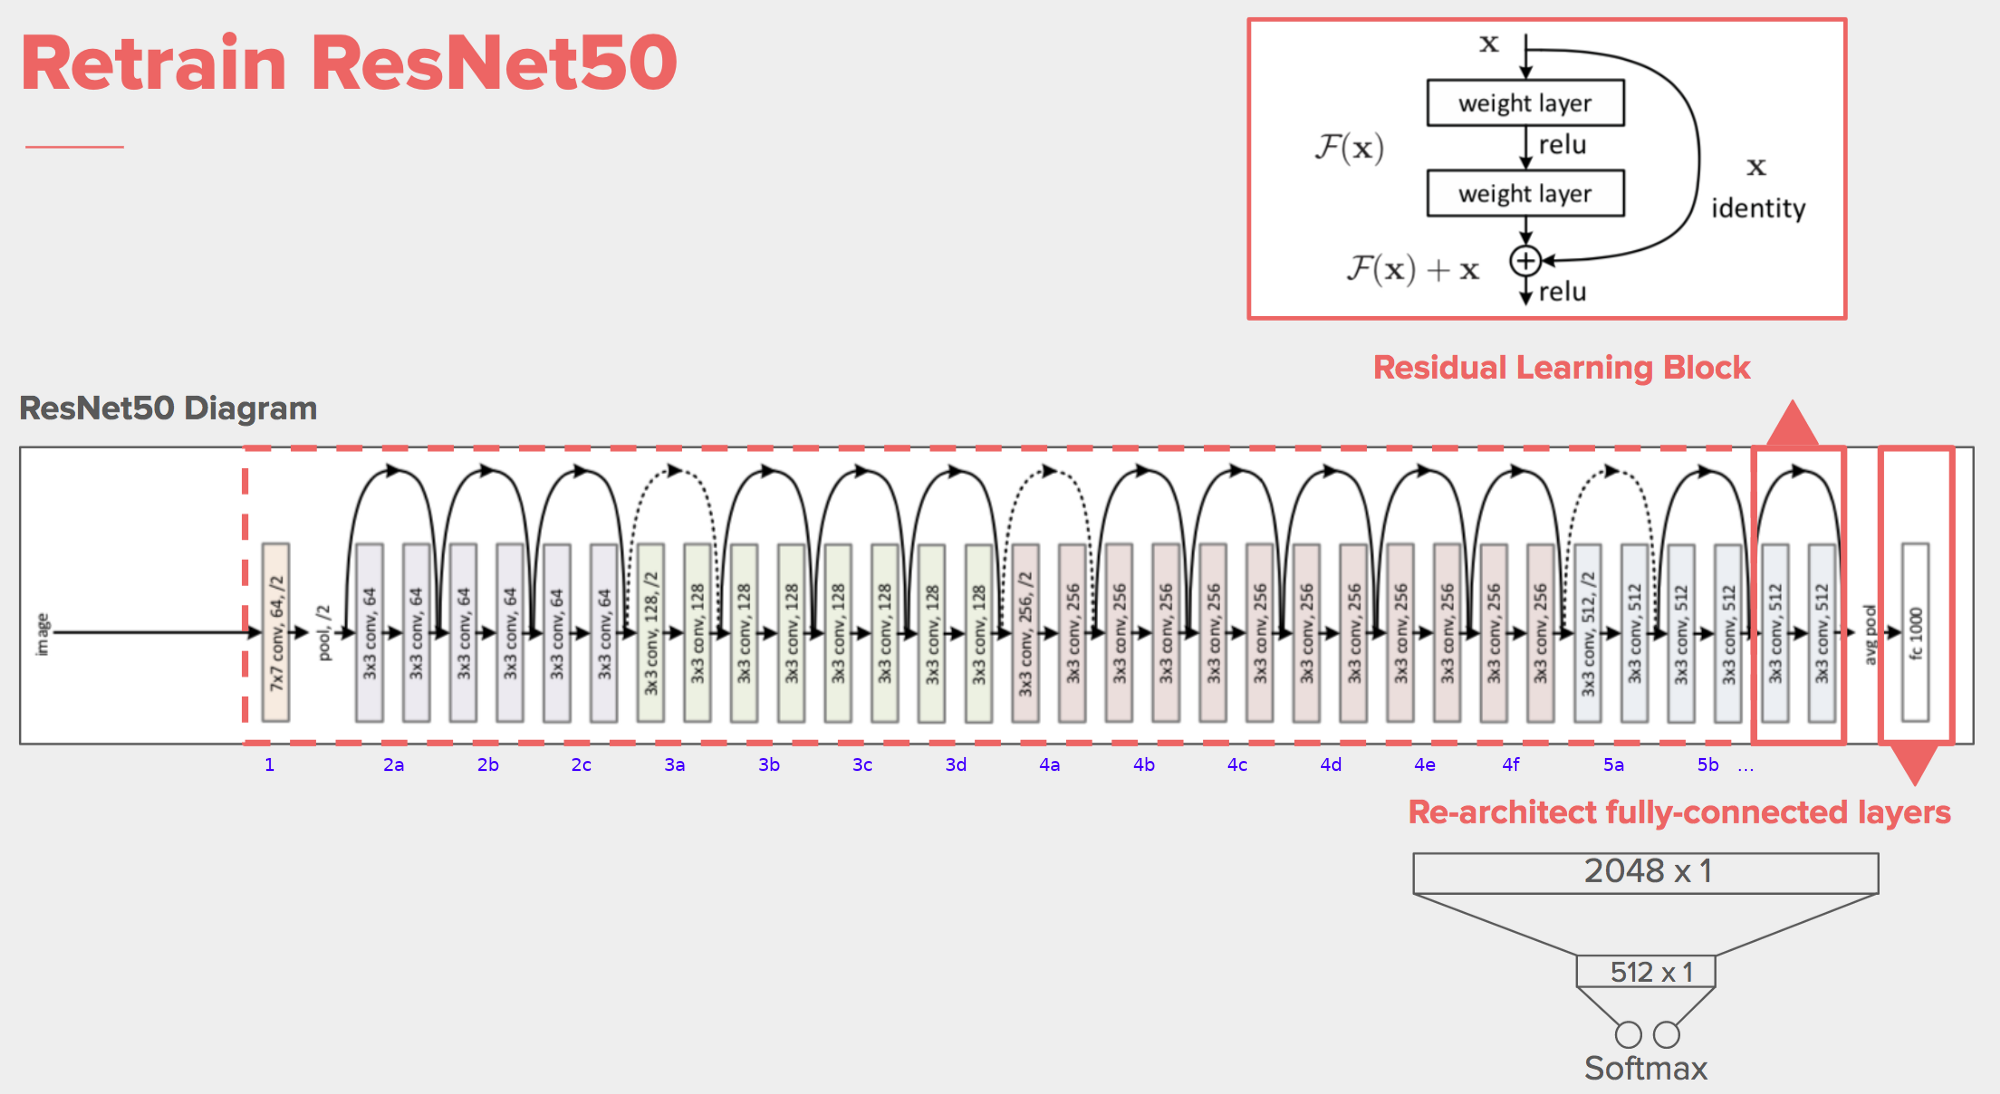





---

In [4]:
import cv2
import numpy as np
import os
# Libraries
from tensorflow.keras.applications import resnet50,ResNet50
from tensorflow.keras.preprocessing import image

model=ResNet50(weights='imagenet', include_top=False, input_shape=(150,150,3))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
img = cv2.imread(r"/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/NORMAL/IM-0115-0001.jpeg")
img

array([[[ 22,  22,  22],
        [ 24,  24,  24],
        [ 24,  24,  24],
        ...,
        [ 96,  96,  96],
        [ 94,  94,  94],
        [ 93,  93,  93]],

       [[ 23,  23,  23],
        [ 24,  24,  24],
        [ 24,  24,  24],
        ...,
        [ 97,  97,  97],
        [ 94,  94,  94],
        [ 92,  92,  92]],

       [[ 24,  24,  24],
        [ 24,  24,  24],
        [ 23,  23,  23],
        ...,
        [ 99,  99,  99],
        [ 96,  96,  96],
        [ 94,  94,  94]],

       ...,

       [[ 49,  49,  49],
        [ 50,  50,  50],
        [ 48,  48,  48],
        ...,
        [119, 119, 119],
        [119, 119, 119],
        [119, 119, 119]],

       [[ 50,  50,  50],
        [ 52,  52,  52],
        [ 53,  53,  53],
        ...,
        [123, 123, 123],
        [124, 124, 124],
        [123, 123, 123]],

       [[ 52,  52,  52],
        [ 53,  53,  53],
        [ 54,  54,  54],
        ...,
        [129, 129, 129],
        [128, 128, 128],
        [127, 127, 127]]

In [6]:
img = cv2.resize(img, (150,150))
img = image.img_to_array(img)
img = resnet50.preprocess_input(np.expand_dims(img.copy(),axis=0))
img = model.predict(img)
img = img.flatten()
img.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


(51200,)

In [ ]:
train_dir = r"/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train"

Y_train = []
X_train = []
label = 0

# 2 for loop, 1 for classes and 1 for images in the class
for i in os.listdir(train_dir): #for class
  for j in os.listdir(train_dir+'/'+i+"/"):
    print(train_dir+'/'+i+'/'+j)
    img=cv2.imread(train_dir+'/'+i+'/'+j)
    img=cv2.resize(img,(150,150))
    img = image.img_to_array(img)
    img = resnet50.preprocess_input(np.expand_dims(img.copy(), axis=0))
    img = model.predict(img)
    X_train.append(img.flatten()/255)
    Y_train.append(label)
label = label+1

Streaming output truncated to the last 5000 lines.
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person1876_bacteria_4760.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person1838_bacteria_4703.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person263_virus_546.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person1916_bacteria_4821.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person258_bacteria_1216.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person274_bacteria_1288.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PNEUMONIA/person1816_bacteria_4674.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/train/PN

In [ ]:
test_dir = r"/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test"

Y_test = []
X_test = []
label = 0

# 2 for loop, 1 for classes and 1 for images in the class
for i in os.listdir(test_dir): #for class
  for j in os.listdir(test_dir+'/'+i+"/"):
    print(test_dir+'/'+i+'/'+j)
    img=cv2.imread(test_dir+'/'+i+'/'+j)
    img=cv2.resize(img,(150,150))
    img = image.img_to_array(img)
    img = resnet50.preprocess_input(np.expand_dims(img.copy(), axis=0))
    img = model.predict(img)
    X_test.append(img.flatten()/255)
    Y_test.append(label)
  label = label+1

/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person118_bacteria_560.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person108_bacteria_507.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person138_bacteria_657.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person1628_virus_2822.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person100_bacteria_480.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person128_bacteria_608.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person127_bacteria_603.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
/content/drive/MyDrive/AI4AnF/Data/Pneumonia/test/PNEUMONIA/person138_bacteria_659.jpeg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39m

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn import linear_model
model = linear_model.LogisticRegression().fit(X_train,Y_train)
pred = model.predict(X_test)
cm = confusion_matrix(Y_test,pred)
print((cm[0,0]+cm[1,1])/(sum(sum(cm))))

ValueError: ignored

## **OPTIONAL**

In [ ]:
import joblib

In [ ]:
joblib.dump(model,"/content/drive/MyDrive/Colab Notebooks/Image/resnet.jl")

In [ ]:
# testing


In [ ]:
img=cv2.imread("/content/drive/MyDrive/TT Library/AI Model/Data/Pneumonia/test/PNEUMONIA/person100_bacteria_477.jpeg")
img=cv2.resize(img,(IMG_SIZE,IMG_SIZE))
img = image.img_to_array(img)
img = preprocess_input(np.expand_dims(img.copy(), axis=0))
img = model.predict(img)
img = img.flatten()/255

In [ ]:
import joblib

In [ ]:
model = joblib.load("/content/drive/MyDrive/Colab Notebooks/Image/resnet.jl")

In [ ]:
model.predict([img])

array([0])

In [ ]:
model.predict_proba([img])

array([[0.51266153, 0.48733847]])

In [ ]:
print(a)

[[0.51266153 0.48733847]]


---
### The End, is the New Start.